In [70]:
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from pathlib import Path
from torchinfo import summary
from finished_stuff.going_modular import data_setter_loader, trainer
from timeit import default_timer as timer
from PIL import Image

In [3]:
torch.__version__

'2.6.0+cu124'

In [7]:
torchvision.__version__

'0.21.0+cu124'

In [2]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [40]:
train_dir = "../data/food/train"
test_dir = "../data/food/test"

In [38]:
#making the manaul transform
manual_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [41]:
train_dataloader , test_dataloader , classes = data_setter_loader.data_setter_loader(train_dir, test_dir, manual_transform, 32, 1)

In [44]:
#makingt he auto transform
weights_trained_model  = torchvision.models.EfficientNet_B0_Weights.DEFAULT
auto_transform = weights_trained_model.transforms()
auto_transform

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

In [46]:
#get Data
train_dataloader , test_dataloader , classes = data_setter_loader.data_setter_loader(train_dir, test_dir, manual_transform, 32, 1)
train_dataloader , test_dataloader , classes

(<torch.utils.data.dataloader.DataLoader at 0x233e8e01940>,
 ['pizza', 'steak', 'sushi'])

In [51]:
#getting the model remeber that the weights oyu write the 09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth name with capitals but for the model itself we write small(lowercase)
model = torchvision.models.efficientnet_b0(weights=weights_trained_model).to(device)
model

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [55]:
summary(model,
        input_size=(1,3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 1000]            --                   True
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1280, 7, 7]      --                   True
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   True
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    864                  True
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    64                   True
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1, 16, 112,

In [57]:
#make the features block untrainable
for param in model.features.parameters() :
    param.requires_grad = False

In [58]:
summary(model,
        input_size=(1, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 1000]            --                   Partial
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1280, 7, 7]      --                   False
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   False
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    (864)                False
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    (64)                 False
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1, 1

In [61]:
#adjust the classifier block to fit our Data
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features=1280, out_features=len(classes))).to(device)
model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=3, bias=True)
)

In [63]:
summary(model,
        input_size=(1, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 3]               --                   Partial
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1280, 7, 7]      --                   False
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   False
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    (864)                False
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    (64)                 False
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1, 1

In [66]:
#training the model
#make OPTIM , LOSS
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

start_time = timer()
model_results  = trainer.training_fn(model, train_dataloader, test_dataloader, loss_fn, optimizer, 5, device)
end_time = timer()
print(f"Training time: {end_time - start_time}")

 20%|██        | 1/5 [00:08<00:35,  8.91s/it]

Epoch: 0 | Train loss: 0.5882 | Train acc: 87.1094 | Test loss: 0.5365 | Test acc: 91.7614


 40%|████      | 2/5 [00:16<00:25,  8.41s/it]

Epoch: 1 | Train loss: 0.5771 | Train acc: 80.0781 | Test loss: 0.5619 | Test acc: 86.6477


 60%|██████    | 3/5 [00:24<00:16,  8.21s/it]

Epoch: 2 | Train loss: 0.4838 | Train acc: 78.5156 | Test loss: 0.4559 | Test acc: 90.7197


 80%|████████  | 4/5 [00:33<00:08,  8.26s/it]

Epoch: 3 | Train loss: 0.4349 | Train acc: 93.7500 | Test loss: 0.4422 | Test acc: 89.6780


100%|██████████| 5/5 [00:41<00:00,  8.37s/it]

Epoch: 4 | Train loss: 0.3808 | Train acc: 95.3125 | Test loss: 0.4586 | Test acc: 87.6894
Training time: 41.85276949999934


In [68]:
try:
    print("is already there ")
    from helper_functions import plot_loss_curves
except:
    print("not there , downlaoding........")
    import requests
    with open("../helper_functions.py", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/helper_functions.py")
        f.write(request.content)
    from helper_functions import plot_loss_curves

is already there 


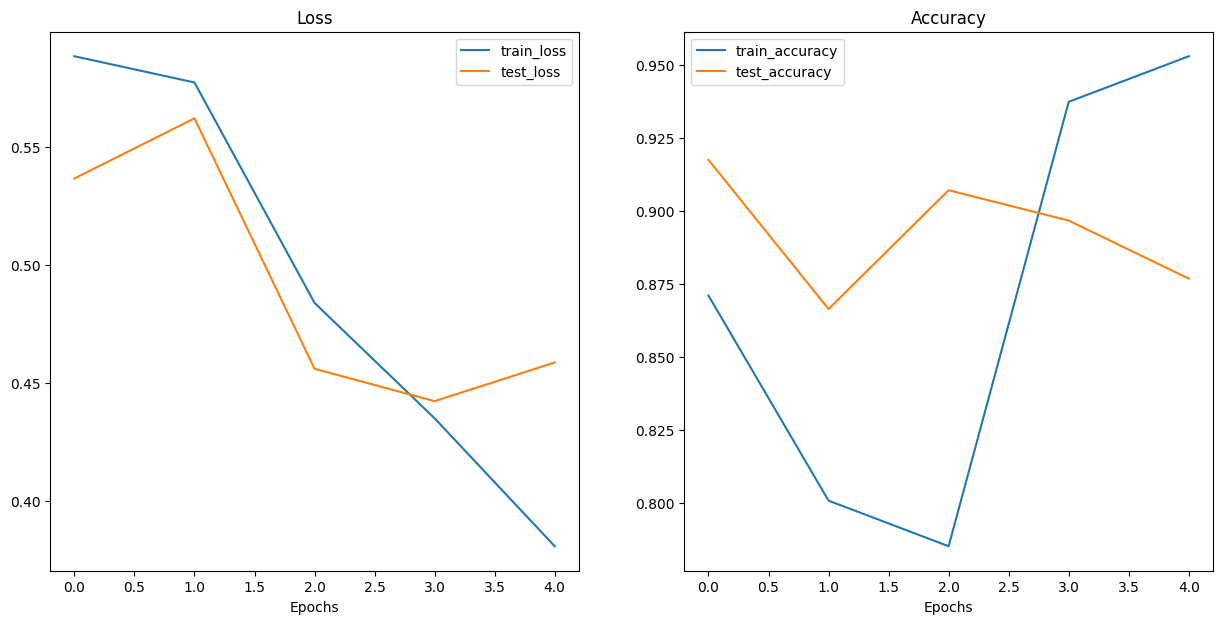

In [69]:
plot_loss_curves(model_results)

In [4]:
%%writefile ../going_modular/random_image_model_test.py
#making a fuction to seee how much the model cna accually guess in random images
def random_image_model_test (model,
                             image_path,
                             class_names,
                             image_size,
                             transform=None,
                             device=device):
    #load image
    img = Image.open(image_path)
    #make transform
    if transform == None :
        image_transform = transforms.Compose([
            transforms.Resize((image_size,image_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])
        ])
    else:
        image_transform = transform
    #model to device and......
    model = model.to(device)
    model.eval()
    with torch.inference_mode():
        img_model_pred = model(image_transform(img).unsqueeze(0).to(device))
    img_model_pred_prob = torch.softmax(img_model_pred, dim=1)
    img_model_pred_label = torch.argmax(img_model_pred_prob, dim=1)
    #make a figure
    plt.figure()
    plt.imshow(img)
    plt.title(f"Pred: {class_names[img_model_pred_label]} | Prob: {img_model_pred_prob.max():.3f}")
    plt.axis(False);



Writing ../going_modular/random_image_model_test.py


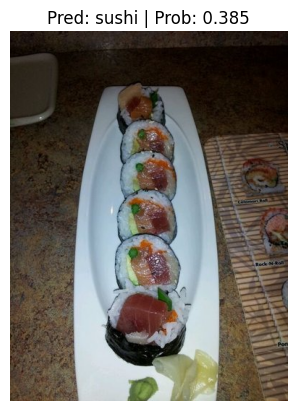

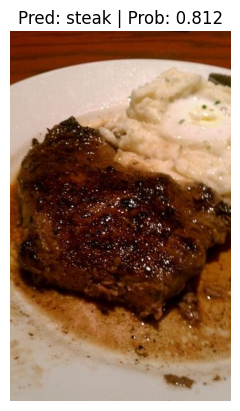

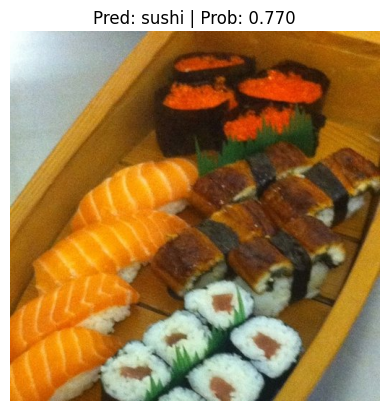

In [74]:
num_rand_samples = 3
list_images = list(Path(test_dir).glob("*/*.jpg"))
random_images = random.sample(list_images , num_rand_samples)
for image_path in random_images:
    random_image_model_test(model,image_path,classes,224,transform=auto_transform,device=device)

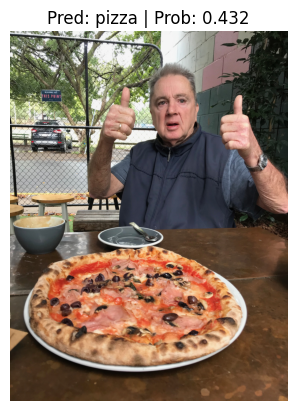

In [77]:
#try a custom image that we have downloaded prev
custom_image_path = "../data/the trying image.jpg"
random_image_model_test(model,custom_image_path,classes,224,transform=auto_transform,device=device)